In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

pd.set_option("display.max_columns", None)

sns.set_theme(style="whitegrid")

In [2]:
file_path = Path(
    "../05_Clean_Data/marketing_data_clean.csv"
)

print("File exists:", file_path.exists())

File exists: True


In [3]:
df = pd.read_csv(file_path)

print("Dataset Shape:", df.shape)

display(df.head())

Dataset Shape: (2240, 46)


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Response,Complain,Country,Income_Was_Missing,Income_Imputed,Education_Standardized,Marital_Status_Group,Country_Standardized,Income_Is_Outlier,Total_Spending,Total_Purchases,Total_Children,Total_Accepted_Campaigns,Customer_Age_Estimated,Age_Group,Income_Group,Enrollment_Year,Enrollment_Month,Enrollment_Quarter,Enrollment_Month_Name,Customer_Tenure_Days
0,1826,1970,Graduation,Divorced,84835.0,0,0,2014-06-16,0,189,104,379,111,189,218,1,4,4,6,1,0,0,0,0,0,1,0,Spain,0,84835.0,Graduate,Divorced,Spain,0,1190,14,0,1,44,35-44,High Income,2014,6,2,June,14
1,1,1961,Graduation,Single,57091.0,0,0,2014-06-15,0,464,5,64,7,0,37,1,7,3,7,5,0,0,0,0,1,1,0,Canada,0,57091.0,Graduate,Single,Canada,0,577,17,0,2,53,45-54,Upper-Middle Income,2014,6,2,June,15
2,10476,1958,Graduation,Married,67267.0,0,1,2014-05-13,0,134,11,59,15,2,30,1,3,2,5,2,0,0,0,0,0,0,0,USA,0,67267.0,Graduate,Married,Usa,0,251,10,1,0,56,55-64,Upper-Middle Income,2014,5,2,May,48
3,1386,1967,Graduation,Together,32474.0,1,1,2014-05-11,0,10,0,1,0,0,0,1,1,0,2,7,0,0,0,0,0,0,0,Australia,0,32474.0,Graduate,Partnered,Australia,0,11,3,2,0,47,45-54,Low Income,2014,5,2,May,50
4,5371,1989,Graduation,Single,21474.0,1,0,2014-04-08,0,6,16,24,11,0,34,2,3,1,2,7,1,0,0,0,0,1,0,Spain,0,21474.0,Graduate,Single,Spain,0,91,6,1,2,25,25-34,Low Income,2014,4,2,April,83


In [5]:
print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])

print("\nData Types:")
df.info()
print(df.columns.tolist())

Total Rows: 2240
Total Columns: 46

Data Types:
<class 'pandas.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 46 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   ID                        2240 non-null   int64  
 1   Year_Birth                2240 non-null   int64  
 2   Education                 2240 non-null   str    
 3   Marital_Status            2240 non-null   str    
 4   Income                    2216 non-null   float64
 5   Kidhome                   2240 non-null   int64  
 6   Teenhome                  2240 non-null   int64  
 7   Dt_Customer               2240 non-null   str    
 8   Recency                   2240 non-null   int64  
 9   MntWines                  2240 non-null   int64  
 10  MntFruits                 2240 non-null   int64  
 11  MntMeatProducts           2240 non-null   int64  
 12  MntFishProducts           2240 non-null   int64  
 13  MntSweetProducts          

In [6]:
total_customers = df["ID"].nunique()

total_spending = df["Total_Spending"].sum()

total_purchases = df["Total_Purchases"].sum()

avg_spending = df["Total_Spending"].mean()

avg_purchases = df["Total_Purchases"].mean()

response_rate = df["Response"].mean() * 100

print("Total Customers:", total_customers)

print("Total Spending:", round(total_spending, 2))

print("Total Purchases:", total_purchases)

print("Average Spending:", round(avg_spending, 2))

print("Average Purchases:", round(avg_purchases, 2))

print("Campaign Response Rate:", round(response_rate, 2), "%")

Total Customers: 2240
Total Spending: 1356988
Total Purchases: 28083
Average Spending: 605.8
Average Purchases: 12.54
Campaign Response Rate: 14.91 %


In [7]:
kpi_summary = pd.DataFrame({
    "KPI": [
        "Total Customers",
        "Total Spending",
        "Total Purchases",
        "Average Spending",
        "Average Purchases",
        "Campaign Response Rate (%)"
    ],
    "Value": [
        total_customers,
        total_spending,
        total_purchases,
        avg_spending,
        avg_purchases,
        response_rate
    ]
})

display(kpi_summary.round(2))

,KPI,Value
0,Total Customers,2240.00
1,Total Spending,1356988.00
2,Total Purchases,28083.00
3,Average Spending,605.80
4,Average Purchases,12.54
5,Campaign Response Rate (%),14.91


In [9]:
numerical_columns = [
    "Income",
    "Total_Spending",
    "Total_Purchases",
    "Recency",
    "Customer_Age_Estimated"
]
display(
    df[numerical_columns].describe().T
)

,count,mean,std,min,25%,50%,75%,max
Income,2216.0,52247.251354,25173.076661,1730.0,35303.00,51381.5,68522.0,666666.0
Total_Spending,2240.0,605.798214,602.249288,5.0,68.75,396.0,1045.5,2525.0
Total_Purchases,2240.0,12.537054,7.205741,0.0,6.00,12.0,18.0,32.0
Recency,2240.0,49.109375,28.962453,0.0,24.00,49.0,74.0,99.0
Customer_Age_Estimated,2240.0,45.194196,11.984069,18.0,37.00,44.0,55.0,121.0


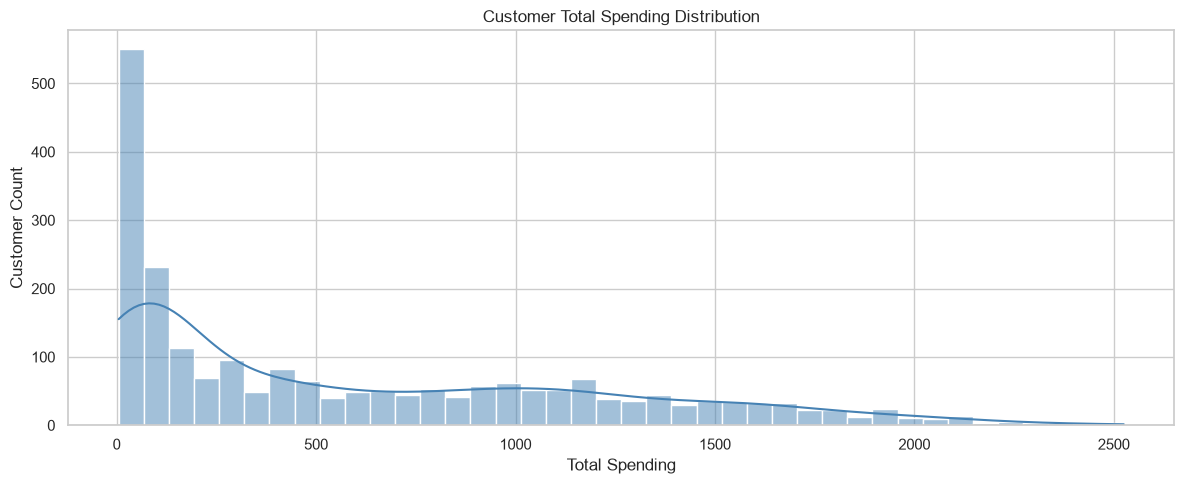

In [10]:
plt.figure(figsize=(12, 5))

sns.histplot(
    data=df,
    x="Total_Spending",
    bins=40,
    kde=True,
    color="steelblue"
)

plt.title("Customer Total Spending Distribution")
plt.xlabel("Total Spending")
plt.ylabel("Customer Count")

plt.tight_layout()
plt.show()

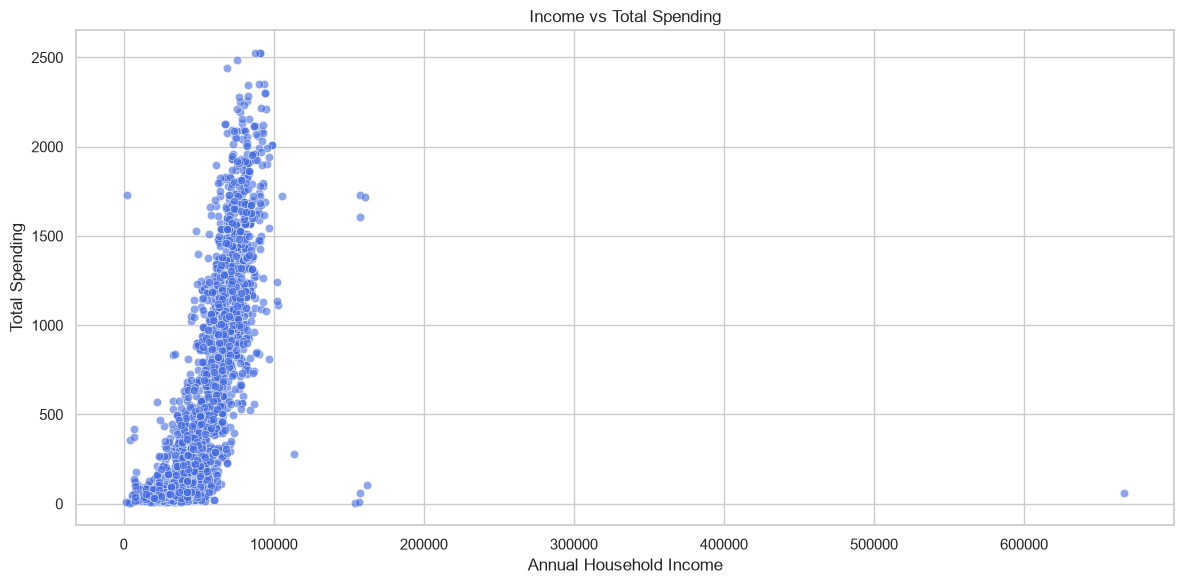

In [11]:
plt.figure(figsize=(12, 6))

sns.scatterplot(
    data=df,
    x="Income",
    y="Total_Spending",
    alpha=0.6,
    color="royalblue"
)

plt.title("Income vs Total Spending")
plt.xlabel("Annual Household Income")
plt.ylabel("Total Spending")

plt.tight_layout()
plt.show()

In [12]:
categorical_columns = [
    "Education_Standardized",
    "Marital_Status_Group",
    "Country_Standardized",
    "Age_Group",
    "Income_Group"
]

for col in categorical_columns:

    print(f"\n===== {col} =====")

    display(
        df[col].value_counts(dropna=False)
    )


===== Education_Standardized =====


Education_Standardized
Graduate           1127
Doctorate           486
Master's Degree     370
Second Cycle        203
Basic Education      54
Name: count, dtype: int64


===== Marital_Status_Group =====


Marital_Status_Group
Married         864
Partnered       580
Single          480
Divorced        232
Widowed          77
Unknown           4
Living Alone      3
Name: count, dtype: int64


===== Country_Standardized =====


Country_Standardized
Spain           1095
Saudi Arabia     337
Canada           268
Australia        160
India            148
Germany          120
Usa              109
Mexico             3
Name: count, dtype: int64


===== Age_Group =====


Age_Group
35-44    740
45-54    506
55-64    460
25-34    363
65+      107
18-24     61
NaN        3
Name: count, dtype: int64


===== Income_Group =====


Income_Group
High Income            554
Upper-Middle Income    554
Low Income             554
Lower-Middle Income    554
NaN                     24
Name: count, dtype: int64

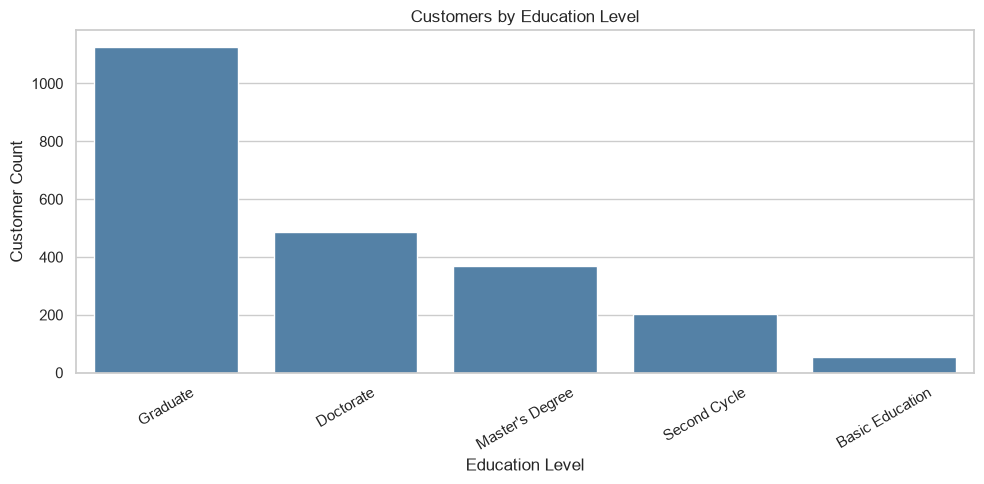

In [13]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x="Education_Standardized",
    order=df["Education_Standardized"].value_counts().index,
    color="steelblue"
)

plt.title("Customers by Education Level")
plt.xlabel("Education Level")
plt.ylabel("Customer Count")

plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

In [14]:
eda_quality = pd.DataFrame({
    "Check": [
        "Total Rows",
        "Unique Customers",
        "Duplicate IDs",
        "Missing Income",
        "Missing Total Spending",
        "Missing Age Group"
    ],
    "Value": [
        len(df),
        df["ID"].nunique(),
        df["ID"].duplicated().sum(),
        df["Income"].isna().sum(),
        df["Total_Spending"].isna().sum(),
        df["Age_Group"].isna().sum()
    ]
})

display(eda_quality)

,Check,Value
0,Total Rows,2240
1,Unique Customers,2240
2,Duplicate IDs,0
3,Missing Income,24
4,Missing Total Spending,0
5,Missing Age Group,3
